# 07 · Huấn luyện mini-GPT trên Truyện Kiều

**Vị trí trong luồng dữ liệu:** toàn bộ – văn bản → token → embedding (+ vị trí) → N khối Transformer → logits → token tiếp theo

Đã đến lúc ghép mọi mảnh lại và cho mô hình học. Trong notebook này bạn sẽ:

1. Dựng `MiniGPT` từ `GPTConfig` và đếm tham số từng phần.
2. Chuẩn bị dữ liệu: chia train/val, tạo batch `(x, y)` trong đó `y` là `x` dịch sang phải 1 token.
3. Hiểu vì sao loss lúc khởi tạo xấp xỉ `ln(4000) ≈ 8,3`.
4. Huấn luyện khoảng 2 phút trên CPU, vẽ đường loss, lưu checkpoint.
5. Sinh thử văn bản, đo chính tả và kiểm tra mô hình "sáng tác" hay "chép bài".
6. Lặp lại thử nghiệm embedding (a)/(b) của notebook 02 trên mô hình đầy đủ.

⏱ Thời gian chạy: khoảng 6 phút trên CPU laptop, trong đó mục 6 chiếm khoảng 4 phút; đặt `RUN_COMPARISON = False`
để bỏ qua mục đó.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "vietformer").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import math

import matplotlib.pyplot as plt
import torch

from vietformer import viz
from vietformer.data import encode_corpus, get_tokenizer, load_corpus
from vietformer.generate import generate_text
from vietformer.model import GPTConfig, MiniGPT
from vietformer.train import get_batch, lr_at, split_train_val, train
from vietformer.utils import CHECKPOINT_DIR, count_parameters, get_device, portable_path, set_seed
from vietformer.word_vectors import build_embedding_matrix, load_word_vectors

viz.set_style()
set_seed(42)
device = get_device()
print("Thiết bị:", device)

RUN_COMPARISON = True  # đặt False để bỏ qua mục 6 (tiết kiệm vài phút)

Thiết bị: cpu


## 1. Mô hình

Mọi siêu tham số nằm trong **một** dataclass `GPTConfig` (`src/vietformer/model.py`). Giá trị mặc định: 4 khối,
4 head, `d_model = 128`, ngữ cảnh `block_size = 64` token (khoảng 7 câu thơ), dropout 0,1.

In [2]:
tokenizer = get_tokenizer()
config = GPTConfig(vocab_size=tokenizer.vocab_size)
model = MiniGPT(config).to(device)
print(config, "\n")
print(model)

GPTConfig(vocab_size=4000, block_size=64, n_layer=4, n_head=4, d_model=128, dropout=0.1, pos_encoding='learned', pretrained_dim=None, freeze_embedding=False) 

MiniGPT(
  (tok_emb): TokenEmbedding(
    (table): Embedding(4000, 128)
    (proj): Identity()
  )
  (pos_emb): LearnedPositionalEmbedding(
    (table): Embedding(64, 128)
  )
  (drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x TransformerBlock(
      (ln1): LayerNorm()
      (attn): MultiHeadAttention(
        (query): Linear(in_features=128, out_features=128, bias=False)
        (key): Linear(in_features=128, out_features=128, bias=False)
        (value): Linear(in_features=128, out_features=128, bias=False)
        (proj): Linear(in_features=128, out_features=128, bias=True)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): LayerNorm()
      (ffn): FeedForward(
        (net): Sequential(
          (0): Linear(in_features

In [3]:
parts = {
    "token embedding": model.tok_emb,
    "positional embedding": model.pos_emb,
    f"{config.n_layer} khối Transformer": model.blocks,
    "LayerNorm cuối": model.ln_f,
    "lm_head (lớp đầu ra)": model.lm_head,
}
total = count_parameters(model)
for name, module in parts.items():
    n = count_parameters(module)
    print(f"{name:24} {n:>10,} ({n / total:5.1%})")
print(f"{'tổng':24} {total:>10,}")

token embedding             512,000 (28.0%)
positional embedding          8,192 ( 0.4%)
4 khối Transformer          791,552 (43.3%)
LayerNorm cuối                  256 ( 0.0%)
lm_head (lớp đầu ra)        516,000 (28.2%)
tổng                      1,828,000


Hơn một nửa số tham số nằm ở hai đầu: bảng embedding (`4000 × 128`) và lớp đầu ra (`128 × 4000`). Đây là đặc điểm
của mô hình nhỏ có vocab lớn. Ở các mô hình lớn như GPT-3, phần lớn tham số nằm trong các khối Transformer.

## 2. Dữ liệu: train/val và batch

Toàn bộ Truyện Kiều được mã hóa thành một dãy token id dài. **90% đầu** dùng để huấn luyện; **10% cuối** (đoạn kết
của truyện) làm tập **validation** – mô hình không bao giờ học trên phần này, nên loss trên val cho biết mô hình
khái quát hóa tốt đến đâu với câu thơ nó chưa từng thấy.

> Tokenizer được huấn luyện trên toàn bộ corpus (kể cả phần val) cho đơn giản. Với vocab 4.000 điều này gần như
> không ảnh hưởng, nhưng trong dự án thật bạn nên chỉ dùng tập train.

In [4]:
data = encode_corpus(tokenizer)
train_data, val_data = split_train_val(data, val_fraction=0.1)
print(f"Tổng {len(data):,} token → train {len(train_data):,}, val {len(val_data):,}\n")
print("Đầu tập val:\n" + tokenizer.decode(val_data[:40]))

Tổng 29,693 token → train 26,723, val 2,970

Đầu tập val:
biết vân mồng làm sao.
Nghe tường ngành ngọn tiêu hao,
Lòng riêng chàng luống lao đao thẫn thờ.
Xót thay chiếc lá bơ vơ,
Kiếp trần biết giũ bao giờ cho


Mỗi batch gồm `B` đoạn ngẫu nhiên dài `T = block_size` token. Nhãn `y` chính là `x` dịch sang phải 1 token, nên một
đoạn dài `T` chứa `T` bài tập "đoán chữ tiếp theo" cùng lúc – nhờ causal mask, ở vị trí `t` mô hình chỉ thấy `x[0..t]`:

In [5]:
x, y = get_batch(train_data, block_size=10, batch_size=1)
print("x:", tokenizer.display_tokens(x[0]))
print("y:", tokenizer.display_tokens(y[0]), "\n")
for t in range(6):
    context = " ".join(tokenizer.display_tokens(x[0, : t + 1]))
    print(f"{context:>40}  →  {tokenizer.display_tokens(y[0, t : t + 1])[0]}")

x: ['trướng', 'hồng', 'tẩm', 'hoa', '.', '↵', 'Rõ', 'màu', 'trong', 'ngọc']
y: ['hồng', 'tẩm', 'hoa', '.', '↵', 'Rõ', 'màu', 'trong', 'ngọc', 'trắng'] 

                                  trướng  →  hồng
                             trướng hồng  →  tẩm
                         trướng hồng tẩm  →  hoa
                     trướng hồng tẩm hoa  →  .
                   trướng hồng tẩm hoa .  →  ↵
                 trướng hồng tẩm hoa . ↵  →  Rõ


## 3. Loss lúc khởi tạo

Loss là **cross-entropy**: với mỗi vị trí, lấy xác suất mô hình gán cho token đúng rồi tính `−log` của nó (đúng hẳn:
loss 0; càng sai: loss càng lớn), sau đó lấy trung bình. Lúc khởi tạo, trọng số nhỏ nên logits gần bằng nhau và mô hình
đoán gần như **đều** trên 4.000 token: xác suất cho token đúng ≈ 1/4000, loss ≈ `−log(1/4000) = ln 4000 ≈ 8,29`.
Nếu loss ban đầu lệch xa con số này, nhiều khả năng có lỗi trong code hoặc trong cách khởi tạo.

In [6]:
x, y = get_batch(train_data, config.block_size, batch_size=32, device=device)
logits, loss = model(x, y)
print("logits:", tuple(logits.shape), "  # (B, T, vocab_size)")
print(f"loss ban đầu = {loss.item():.3f}   |   ln({tokenizer.vocab_size}) = {math.log(tokenizer.vocab_size):.3f}")

logits: (32, 64, 4000)   # (B, T, vocab_size)
loss ban đầu = 8.356   |   ln(4000) = 8.294


## 4. Huấn luyện

Hàm `train` (`src/vietformer/train.py`) lặp lại các bước kinh điển:

```python
x, y = get_batch(train_data, block_size, batch_size)   # lấy batch ngẫu nhiên
_, loss = model(x, y)                                  # forward: tính loss
optimizer.zero_grad()
loss.backward()                                        # backward: tính gradient
torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # chặn gradient quá lớn
optimizer.step()                                       # cập nhật trọng số
```

Thêm vài chi tiết thường gặp ở các mô hình thật:

* **AdamW** với *weight decay* (kéo nhẹ các ma trận trọng số về 0) – một cách chống overfitting.
* **Learning rate** tăng dần trong 100 bước đầu (*warmup*) rồi giảm dần theo hình cosine (hình dưới).
* Cứ 100 bước đo loss trên train và val; **checkpoint có val loss thấp nhất** được lưu vào `checkpoints/` và được
  nạp lại vào mô hình khi kết thúc (một dạng *early stopping*).

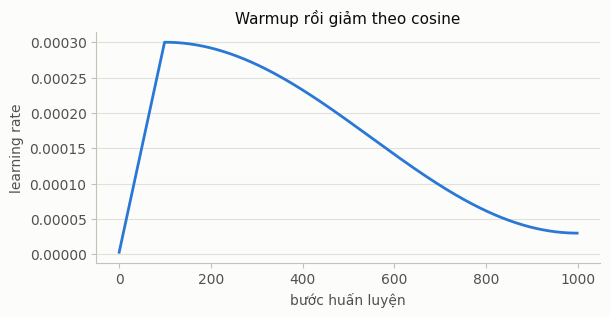

In [7]:
MAX_STEPS, LR = 1000, 3e-4
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(range(MAX_STEPS), [lr_at(s, MAX_STEPS, LR, warmup_steps=100) for s in range(MAX_STEPS)], color=viz.COLORS[0])
ax.set(xlabel="bước huấn luyện", ylabel="learning rate", title="Warmup rồi giảm theo cosine")
ax.grid(axis="y")
plt.show()

Trước khi huấn luyện, xem mô hình "nói" gì với trọng số ngẫu nhiên:

In [8]:
print(generate_text(model, tokenizer, "Trăm năm trong cõi người ta,", max_new_tokens=30, seed=0))

Trăm năm trong cõi người ta, Nay dư trạng ghé hôi hương hổ dư Mấtin thổ Vuốt thiệt nần Nô Rồi vầyọ Xiếtòe vượn kè hôi nh buồng khân trướng Nạnươm Nam


Hoàn toàn vô nghĩa, và còn có những "chữ" không tồn tại. Vocab chủ yếu gồm âm tiết nguyên vẹn, nhưng cũng có khoảng
400 *mảnh* âm tiết (như `ọ`, `òe`, `ươm` – dùng để ghép các âm tiết hiếm). Mô hình chưa học chọn token gần như ngẫu
nhiên nên ghép các mảnh đó vào chữ đứng trước, tạo ra những chữ như "Xiếtòe". Giờ thì huấn luyện – khoảng 2 phút trên CPU:

In [9]:
checkpoint_path = CHECKPOINT_DIR / "minigpt_truyen_kieu.pt"
history = train(
    model, train_data, val_data,
    max_steps=MAX_STEPS, batch_size=32, lr=LR, eval_interval=100,
    checkpoint_path=checkpoint_path,
    checkpoint_extra={"tokenizer_path": portable_path(tokenizer.model_path)},
)

bước     0 | train loss 8.350 | val loss 8.349 |     1s


bước   100 | train loss 6.501 | val loss 6.567 |    13s


bước   200 | train loss 5.476 | val loss 5.769 |    25s


bước   300 | train loss 4.885 | val loss 5.554 |    36s


bước   400 | train loss 4.414 | val loss 5.414 |    48s


bước   500 | train loss 4.090 | val loss 5.381 |    59s


bước   600 | train loss 3.877 | val loss 5.378 |    71s


bước   700 | train loss 3.732 | val loss 5.373 |    82s


bước   800 | train loss 3.631 | val loss 5.388 |    94s


bước   900 | train loss 3.571 | val loss 5.387 |   105s


bước  1000 | train loss 3.528 | val loss 5.391 |   116s
Xong sau 116s. Val loss tốt nhất 5.373 ở bước 700.


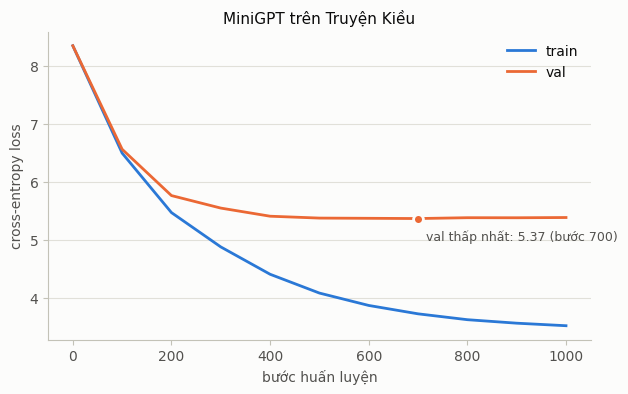

In [10]:
viz.plot_loss(history, title="MiniGPT trên Truyện Kiều")
plt.show()

Đọc đường loss:

* Lúc đầu cả hai đường cùng giảm nhanh từ 8,3: mô hình học những điều dễ nhất trước (dấu phẩy, xuống dòng, các chữ
  hay gặp như "một", "nàng", "rằng").
* Từ khoảng bước 200, **khoảng cách giữa train và val mở rộng dần**: train loss tiếp tục giảm (xuống khoảng 3,5) nhưng
  val loss dừng lại quanh 5,4. Mô hình bắt đầu học thuộc những gì chỉ có trong tập train – dấu hiệu của **overfitting**.
  Với 27 nghìn token và 1,8 triệu tham số, điều này đến rất sớm: 1.000 bước × 32 chuỗi × 64 token ≈ đọc lại toàn bộ
  tập train 77 lần (77 epoch).
* Checkpoint ở bước có val loss thấp nhất đã được lưu và nạp lại vào mô hình.
* Val loss ≈ 5,37 nghĩa là trung bình mô hình gán xác suất khoảng `e^(−5,37) ≈ 0,5%` cho token đúng: nó "phân vân" như
  khi chọn ngẫu nhiên giữa khoảng 215 token (gọi là *perplexity*), so với 4.000 lúc chưa học.

## 5. Sinh văn bản

Mô hình trong bộ nhớ lúc này là checkpoint có val loss thấp nhất. Cho nó câu mở đầu nổi tiếng của Truyện Kiều:

In [11]:
prompt = "Trăm năm trong cõi người ta,"
samples = [generate_text(model, tokenizer, prompt, max_new_tokens=60, temperature=0.8, top_k=50, seed=s) for s in range(3)]
for s in samples:
    print(s, "\n")

Trăm năm trong cõi người ta,
Mụ càng ngẩn ngơ ngẩn chơi!
Nàng càng đau lòng thì, mặt,
Đã trong là nơi hỏi xong mình?
Đã đành riêng sau mới lạ nàng!
Đã đành trong, nàng mới là mình!
Sinh càng dập càng nồng đồng,
Nàng rằng: Lời vàng chẳng 

Trăm năm trong cõi người ta,
Người sao đành rồi lại tính lại đây!
Trước phải điều gần nào đã thấy người.
Trong tay đã đứng nói một lời.
Nàng từ nhà đất, bài,
Rằng: Một lời nàng ra đi thì.
Đã trong thần giây giở đến điều.
Giác Duyên đâu 

Trăm năm trong cõi người ta,
Nghĩ có hai lời nàng mới là gì?
Nỗi lòng chẳng giữ giàng cho đến nhà.
Nàng rằng: Những là duyên,
Nghĩ mình một ngày cũng như rày cho!
Cũng mà lại nối lời nàng,
Một lời như đã đến đây,
Nghĩ có đây?
 



Mô hình đã học được khá nhiều thứ chỉ từ 27 nghìn token: xuống dòng sau dấu phẩy hoặc dấu chấm, độ dài câu xấp xỉ
nhịp 6–8, cách dùng "Nàng rằng:", "Chàng rằng:", các cụm từ quen thuộc. Nhưng các câu chưa mạch lạc về nghĩa.

Hai câu hỏi nên kiểm tra bằng số đo thay vì bằng mắt, trên 10 đoạn sinh ra:

* **Chính tả:** bao nhiêu phần trăm âm tiết sinh ra là âm tiết có thật (có trong Truyện Kiều)?
* **Sáng tác hay chép bài?** Với corpus nhỏ, mô hình rất dễ học thuộc. Bao nhiêu phần trăm cụm 4 âm tiết liên tiếp
  trong văn bản sinh ra xuất hiện y hệt trong Truyện Kiều?

In [12]:
def syllables(text):
    """Tách âm tiết theo khoảng trắng, bỏ dấu câu dính kèm, viết thường."""
    return [w.strip(".,!?:;\"'").lower() for w in text.split() if w.strip(".,!?:;\"'")]


def ngrams(words, n=4):
    return {tuple(words[i : i + n]) for i in range(len(words) - n + 1)}


corpus_syllables = syllables(load_corpus())
kieu_syllables, kieu_4grams = set(corpus_syllables), ngrams(corpus_syllables)


def check(m, n_samples=10):
    valid, copied = [], []
    for seed in range(n_samples):
        words = syllables(generate_text(m, tokenizer, prompt, max_new_tokens=60, temperature=0.8, top_k=50, seed=seed)[len(prompt):])
        valid.append(sum(w in kieu_syllables for w in words) / len(words))
        copied.append(len(ngrams(words) & kieu_4grams) / max(1, len(ngrams(words))))
    return sum(valid) / n_samples, sum(copied) / n_samples


set_seed(0)
untrained = MiniGPT(config).to(device)
print(f"{'':18}{'âm tiết có thật':>17}{'cụm 4 âm tiết chép nguyên văn':>32}")
for name, m in [("chưa huấn luyện", untrained), ("đã huấn luyện", model)]:
    valid, copied = check(m)
    print(f"{name:18}{valid:>17.1%}{copied:>32.1%}")

                    âm tiết có thật   cụm 4 âm tiết chép nguyên văn


chưa huấn luyện               84.0%                            0.0%


đã huấn luyện                100.0%                            0.7%


* **Chính tả:** mô hình chưa học sinh ra khoảng 16% "âm tiết" không có thật; sau khi học, 100% âm tiết sinh ra đều có
  trong Truyện Kiều. Mô hình đã học được rằng các mảnh âm tiết hầu như không bao giờ đứng một mình.
* **Không chép bài:** chưa tới 1% cụm 4 âm tiết trùng nguyên văn Truyện Kiều. Mô hình ghép các từ quen thuộc theo cách
  mới, nên câu "nghe như Kiều" nhưng chưa có nghĩa. (Notebook 08 cho thấy hạ temperature thì mô hình chép nhiều hơn.)

## 6. Thử nghiệm (a)/(b) trên mô hình đầy đủ: học từ đầu hay khởi tạo từ fastText?

Ở notebook 02, với mô hình bigram, embedding học từ đầu thắng. Liệu kết luận đó còn đúng khi đã có attention nhìn ngữ
cảnh? Ta huấn luyện thêm hai mô hình với **cùng** cấu hình và cùng số bước, chỉ khác phần embedding:

* **(b) fastText, freeze:** bảng `4000 × 300` từ fastText, đóng băng, cộng lớp chiếu `300 → 128`;
* **(b) fastText, finetune:** như trên nhưng cho học tiếp cả bảng.

Mô hình vừa huấn luyện ở mục 4 chính là **(a) học từ đầu**.

--- (b) fastText, freeze: 1,354,400 tham số được huấn luyện


    val loss tốt nhất 5.114 ở bước 1000
--- (b) fastText, finetune: 2,554,400 tham số được huấn luyện


    val loss tốt nhất 5.288 ở bước 900


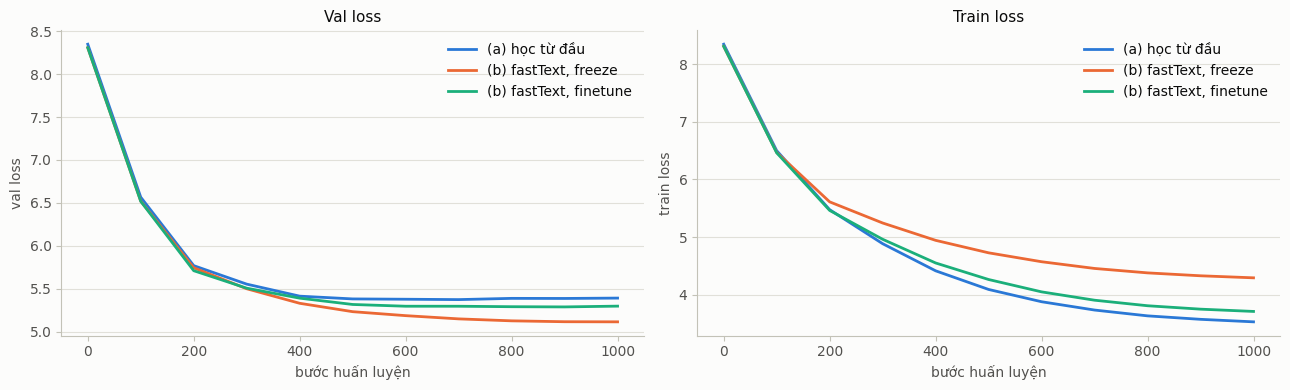

In [13]:
histories = {"(a) học từ đầu": history}
if RUN_COMPARISON:
    word_vectors = load_word_vectors()
    matrix, coverage = build_embedding_matrix(tokenizer, word_vectors)
    for name, freeze in [("(b) fastText, freeze", True), ("(b) fastText, finetune", False)]:
        set_seed(42)
        cfg = GPTConfig(vocab_size=tokenizer.vocab_size, pretrained_dim=word_vectors.dim, freeze_embedding=freeze)
        m = MiniGPT(cfg)
        m.tok_emb.load_vectors(matrix)
        m.to(device)
        print(f"--- {name}: {count_parameters(m, trainable_only=True):,} tham số được huấn luyện")
        histories[name] = train(m, train_data, val_data, max_steps=MAX_STEPS, lr=LR, eval_interval=100, verbose=False)
        print(f"    val loss tốt nhất {histories[name]['best_val_loss']:.3f} ở bước {histories[name]['best_step']}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    viz.plot_loss_comparison(histories, key="val_loss", ax=axes[0], title="Val loss")
    viz.plot_loss_comparison(histories, key="train_loss", ax=axes[1], title="Train loss")
    plt.tight_layout()
    plt.show()

| Embedding | Tham số được học | Val loss tốt nhất |
|---|---|---|
| (a) học từ đầu | 1.828.000 | 5,37 |
| (b) fastText, freeze | 1.354.400 | **5,11** |
| (b) fastText, finetune | 2.554.400 | 5,29 |

Lần này kết quả **đổi chiều** so với mô hình bigram ở notebook 02: fastText đóng băng tốt nhất, sau đó là finetune,
cuối cùng mới là học từ đầu. Vì sao?

* Trong MiniGPT, việc đoán chữ tiếp theo do attention và các khối Transformer đảm nhận, dựa trên cả ngữ cảnh. Embedding
  chỉ cần cho biết token *là gì*, và đó đúng là thế mạnh của fastText ("nàng" gần "chàng", "trăng" gần "nguyệt"). Trong
  mô hình bigram thì khác: embedding phải tự mã hóa luôn cả thông tin "chữ nào hay đứng sau".
* Đóng băng bảng `4000 × 300` làm số tham số được học **ít hơn** cả mô hình (a) gần nửa triệu – một cách **chống
  overfitting**. Đồ thị bên phải cho thấy bản freeze có train loss *cao hơn* hai bản kia nhưng val loss *thấp hơn*: học
  thuộc kém hơn, khái quát tốt hơn.
* Bản finetune được cập nhật cả 1,2 triệu số của bảng 300 chiều nên có thể dần rời xa tri thức ban đầu của fastText và
  học thuộc giống bản (a), chỉ chậm hơn.

Bài học chung của notebook 02 và 07: không có câu trả lời "luôn đúng". Vector có sẵn có giúp hay không phụ thuộc vào
mô hình, lượng dữ liệu và cách dùng, nên hãy thử và đo trên tập val.

## Tóm tắt

* `MiniGPT` = embedding + vị trí → N khối Transformer → LayerNorm → `lm_head`; mọi siêu tham số trong `GPTConfig`.
* Huấn luyện = lặp lại forward → loss → backward → cập nhật, trên các batch `(x, y)` với `y` là `x` dịch 1 token.
* Loss ban đầu ≈ `ln(vocab_size)` là một phép kiểm tra nhanh rằng code đúng.
* Luôn theo dõi **val loss**: train loss giảm mãi chưa chắc là tốt. Với dữ liệu nhỏ, overfitting đến rất sớm.
* Checkpoint tốt nhất nằm ở `checkpoints/minigpt_truyen_kieu.pt`; notebook 08 sẽ dùng nó.

**Tiếp theo:** notebook 08 – điều khiển việc sinh văn bản và nhìn vào bên trong attention của mô hình đã học.

---

## Bài tập

Đáp án: `solutions/07_train_mini_gpt.md`

**Bài 1.** Huấn luyện lại với `pos_encoding="sinusoidal"` (600 bước là đủ để so sánh) và so sánh đường val loss với
learned positional embedding. Cái nào học nhanh hơn lúc đầu? Vì sao?

In [14]:
# TODO: cfg_sin = GPTConfig(vocab_size=tokenizer.vocab_size, pos_encoding="sinusoidal") ...

**Bài 2.** Train loss tiếp tục giảm nhưng val loss tăng trở lại sau vài trăm bước. Hãy nêu ít nhất **ba** cách giảm
overfitting trong trường hợp này và thử một cách (ví dụ tăng `dropout` lên 0,3, hoặc giảm `d_model` xuống 64).

In [15]:
# TODO: thử một cách giảm overfitting và so sánh best_val_loss

**Bài 3.** Tính bằng tay số tham số của `MiniGPT` với `n_layer=2, d_model=64, vocab_size=4000, block_size=32` (gợi ý:
dùng các công thức ở notebook 06), rồi kiểm tra bằng `count_parameters`.